<a href="https://colab.research.google.com/github/aryaaaaaan1/Ai-in-cyber-security-assignment-3/blob/main/ENSP355_Lab3_Aryan_Singh.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Q1. CNN, RNN/LSTM and GAN Concept Matching (5 marks)

| Model | Suitable data | Cyber-security example |
|---|---|---|
| CNN | Images / grid-like data | Malware image classification |
| RNN / LSTM | Sequences / logs / time series | Sequential intrusion or authentication-log analysis |
| GAN | Synthetic-data generation | Generate controlled synthetic attack samples |
| Dense Network | Small numeric feature table | Normal/Attack classification in this lab |

**Why a dense network is used:** The practical dataset contains four numeric input features for each record. A small dense network is suitable for learning patterns from this fixed-size numeric feature table.


## Q2. Dataset Preparation, Split and Normalization (5 marks)

Load the supplied CSV, select the four numeric features, split the dataset into 75% training and 25% testing data, and standardize the features. The scaler is fitted only on the training data and then applied to the test data to avoid data leakage.

If you are running this notebook in Google Colab, the next cell will ask you to upload `simple_cyber_activity.csv`.


In [1]:
# Imports and reproducibility
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

np.random.seed(42)
tf.random.set_seed(42)

# Upload the supplied CSV in Google Colab.
try:
    from google.colab import files
    uploaded = files.upload()
    csv_file = next(iter(uploaded))
except ImportError:
    # If running outside Colab, place the CSV in the notebook's working directory.
    csv_file = "simple_cyber_activity.csv"

df = pd.read_csv(csv_file)
print("Dataset shape:", df.shape)
display(df.head())


Saving simple_cyber_activity.csv to simple_cyber_activity (1).csv
Dataset shape: (100, 6)


,record_id,failed_logins,login_hour,new_device,data_transfer_mb,label
0,1,4,1,0,164.9,1
1,2,3,3,1,250.6,1
2,3,3,10,0,145.1,0
3,4,2,11,0,397.8,0
4,5,1,3,0,409.3,0


In [2]:
# Inspect dataset structure and class distribution
print("Dataset information:")
df.info()

print("\\nMissing values by column:")
display(df.isnull().sum().to_frame("missing_values"))

print("\\nClass counts (0 = Normal, 1 = Attack):")
display(df["label"].value_counts().sort_index().rename(index={0: "Normal", 1: "Attack"}).to_frame("count"))

# The lab dataset should contain these four numeric input features and a binary label.
features = [
    "failed_logins",
    "login_hour",
    "new_device",
    "data_transfer_mb"
]
required_columns = features + ["label"]
missing_columns = [col for col in required_columns if col not in df.columns]
if missing_columns:
    raise ValueError(f"Dataset is missing required columns: {missing_columns}")

# Remove rows with missing values in the selected inputs/target, if any.
df = df.dropna(subset=required_columns).copy()

X = df[features]
y = df["label"].astype(int)

print("\\nRows used:", len(df))
print("Feature columns:", features)
print("Target values:", sorted(y.unique()))


Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 6 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   record_id         100 non-null    int64  
 1   failed_logins     100 non-null    int64  
 2   login_hour        100 non-null    int64  
 3   new_device        100 non-null    int64  
 4   data_transfer_mb  100 non-null    float64
 5   label             100 non-null    int64  
dtypes: float64(1), int64(5)
memory usage: 4.8 KB
\nMissing values by column:


,missing_values
record_id,0
failed_logins,0
login_hour,0
new_device,0
data_transfer_mb,0
label,0


\nClass counts (0 = Normal, 1 = Attack):


,count
label,
Normal,75
Attack,25


\nRows used: 100
Feature columns: ['failed_logins', 'login_hour', 'new_device', 'data_transfer_mb']
Target values: [np.int64(0), np.int64(1)]


In [3]:
# 75% training / 25% testing split, stratified, random_state=42
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.25,
    random_state=42,
    stratify=y
)

# Fit scaler only on training data; reuse it for test/new records.
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Training shape:", X_train_scaled.shape)
print("Testing shape:", X_test_scaled.shape)
print("Training class counts:")
display(y_train.value_counts().sort_index().rename(index={0: "Normal", 1: "Attack"}).to_frame("count"))

print("\\nNormalization explanation:")
print("StandardScaler transforms features to a comparable scale using the training-set mean and standard deviation.")


Training shape: (75, 4)
Testing shape: (25, 4)
Training class counts:


,count
label,
Normal,56
Attack,19


\nNormalization explanation:
StandardScaler transforms features to a comparable scale using the training-set mean and standard deviation.


## Q3. Build and Train the Neural Network (10 marks)

The network architecture is **4-8-4-1**:
- Input: four feature values
- Hidden layer 1: eight neurons with ReLU activation
- Hidden layer 2: four neurons with ReLU activation
- Output: one sigmoid neuron, producing an Attack probability

The model uses Adam, binary cross-entropy, accuracy, 20 epochs, batch size 8 and `validation_split=0.20`.


In [4]:
# Build the 4-8-4-1 dense neural network
model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(4,)),
    tf.keras.layers.Dense(8, activation="relu"),
    tf.keras.layers.Dense(4, activation="relu"),
    tf.keras.layers.Dense(1, activation="sigmoid")
])

model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

model.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 8)              │            40 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │            36 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │             5 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 81 (324.00 B)

 Trainable params: 81 (324.00 B)

 Non-trainable params: 0 (0.00 B)

In [5]:
# Train for 20 epochs
history = model.fit(
    X_train_scaled,
    y_train,
    validation_split=0.20,
    epochs=20,
    batch_size=8,
    verbose=1
)

print(f"Final training accuracy: {history.history['accuracy'][-1] * 100:.2f}%")
print(f"Final validation accuracy: {history.history['val_accuracy'][-1] * 100:.2f}%")
print("An epoch is one complete pass through the training data.")
print("A batch is a subset of training examples processed before the model updates its weights.")


Epoch 1/20
8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 22ms/step - accuracy: 0.3000 - loss: 0.7544 - val_accuracy: 0.2000 - val_loss: 0.9001
Epoch 2/20
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.3167 - loss: 0.7433 - val_accuracy: 0.2000 - val_loss: 0.8795
Epoch 3/20
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.3000 - loss: 0.7336 - val_accuracy: 0.2667 - val_loss: 0.8604
Epoch 4/20
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.3000 - loss: 0.7246 - val_accuracy: 0.4000 - val_loss: 0.8423
Epoch 5/20
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.3333 - loss: 0.7163 - val_accuracy: 0.4000 - val_loss: 0.8264
Epoch 6/20
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.3667 - loss: 0.7088 - val_accuracy: 0.4000 - val_loss: 0.8122
Epoch 7/20
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - accuracy: 0.3833 - loss: 0.7022 - val_accuracy: 0.4000 - val_loss: 0.7996
Epoch 8/20
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.4000 - loss: 0.6960 - val_accuracy: 0.4667 - val_loss: 0.7882
Epoch

## Q4. Accuracy/Loss Curves and Test Evaluation (10 marks)

Accuracy shows the proportion of correct classifications. Loss measures prediction error. A large gap between training and validation performance may indicate overfitting.


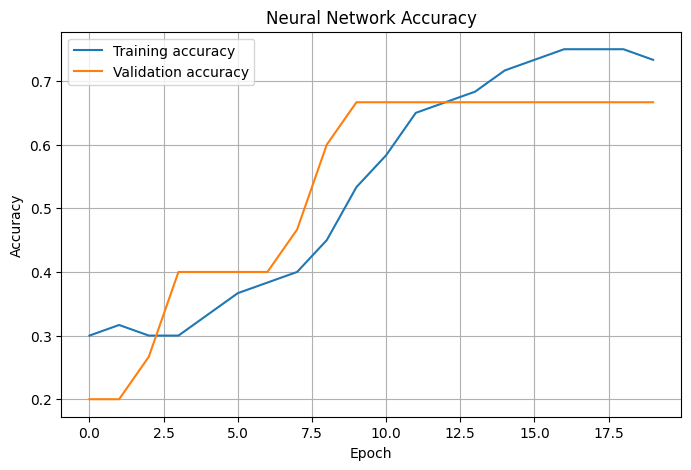

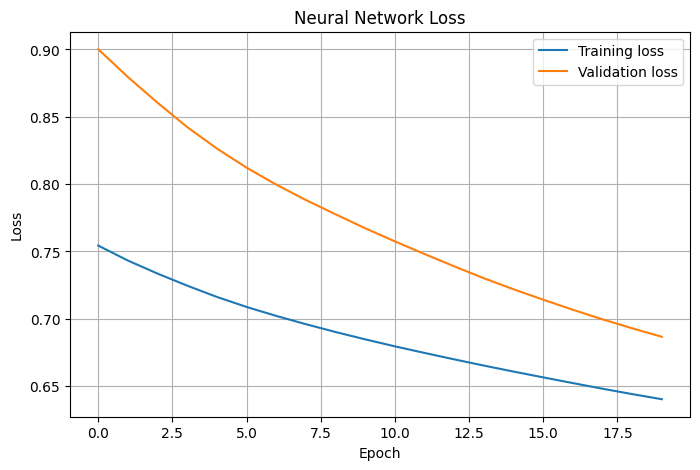

Test accuracy: 88.00%
Test loss: 0.6358


In [6]:
# Plot training and validation accuracy
plt.figure(figsize=(8, 5))
plt.plot(history.history["accuracy"], label="Training accuracy")
plt.plot(history.history["val_accuracy"], label="Validation accuracy")
plt.title("Neural Network Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)
plt.show()

# Plot training and validation loss
plt.figure(figsize=(8, 5))
plt.plot(history.history["loss"], label="Training loss")
plt.plot(history.history["val_loss"], label="Validation loss")
plt.title("Neural Network Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)
plt.show()

# Evaluate on held-out test data
test_loss, test_accuracy = model.evaluate(X_test_scaled, y_test, verbose=0)
print(f"Test accuracy: {test_accuracy * 100:.2f}%")
print(f"Test loss: {test_loss:.4f}")


In [7]:
# Test-set predictions and confusion matrix
test_probabilities = model.predict(X_test_scaled, verbose=0).flatten()
test_predictions = (test_probabilities >= 0.50).astype(int)

print("Confusion matrix (rows = actual, columns = predicted; 0 = Normal, 1 = Attack):")
print(confusion_matrix(y_test, test_predictions))
print("\\nClassification report:")
print(classification_report(y_test, test_predictions, target_names=["Normal", "Attack"], zero_division=0))


Confusion matrix (rows = actual, columns = predicted; 0 = Normal, 1 = Attack):
[[18  1]
 [ 2  4]]
\nClassification report:
              precision    recall  f1-score   support

      Normal       0.90      0.95      0.92        19
      Attack       0.80      0.67      0.73         6

    accuracy                           0.88        25
   macro avg       0.85      0.81      0.83        25
weighted avg       0.88      0.88      0.88        25



### Interpretation of learning curves

Use the graphs and printed test metrics above to complete your lab-file interpretation:

- If training and validation accuracy both improve and remain reasonably close, the model is learning patterns that generalize.
- If training accuracy keeps increasing while validation accuracy stalls or falls, and validation loss rises, this may indicate overfitting.
- If both training and validation performance remain low, the model may be underfitting.

Write your interpretation using the actual curves and metrics produced by your run; exact results can vary.


## Q5. New Predictions and Decision Tree Comparison (10 marks)

The neural-network probability is classified as **Attack** when it is at least 0.50. The same fitted scaler is used for the new records. A Decision Tree (`max_depth=4`, `random_state=42`) is trained on the same training split for comparison.


In [8]:
# Three new cyber-activity records from the lab manual
new_records = pd.DataFrame([
    {"failed_logins": 0, "login_hour": 11, "new_device": 0, "data_transfer_mb": 35},
    {"failed_logins": 7, "login_hour": 1, "new_device": 1, "data_transfer_mb": 250},
    {"failed_logins": 2, "login_hour": 23, "new_device": 1, "data_transfer_mb": 850}
])

# Neural-network predictions
new_scaled = scaler.transform(new_records[features])
probabilities = model.predict(new_scaled, verbose=0).flatten()

results = new_records.copy()
results["nn_probability"] = probabilities.round(3)
results["nn_prediction"] = np.where(probabilities >= 0.50, "Attack", "Normal")

# Decision Tree trained on the same training split
tree = DecisionTreeClassifier(max_depth=4, random_state=42)
tree.fit(X_train, y_train)

tree_test_predictions = tree.predict(X_test)
tree_accuracy = accuracy_score(y_test, tree_test_predictions)

results["tree_prediction"] = np.where(
    tree.predict(new_records[features]) == 1,
    "Attack",
    "Normal"
)

print(f"Neural-network test accuracy: {test_accuracy * 100:.2f}%")
print(f"Decision-tree test accuracy: {tree_accuracy * 100:.2f}%")
display(results)


Neural-network test accuracy: 88.00%
Decision-tree test accuracy: 88.00%


,failed_logins,login_hour,new_device,data_transfer_mb,nn_probability,nn_prediction,tree_prediction
0,0,11,0,35,0.462,Normal,Normal
1,7,1,1,250,0.372,Normal,Attack
2,2,23,1,850,0.830,Attack,Attack


### Comparison and interpretation

Compare the neural-network and Decision Tree test accuracies printed above and inspect the predictions for the three new records.

- **Agreement:** When both models give the same label, confidence in that prediction may increase.
- **Disagreement:** A disagreement should trigger review rather than an automatic decision.
- **Why choose a simpler model?** If a Decision Tree performs similarly, it may be preferable because its decisions are easier to explain.

**Conclusion (complete after running):** Record the actual neural-network accuracy, Decision Tree accuracy, the three predictions and whether the models agree. Explain which model you would prefer for this small dataset and why.


## Submission Checklist

- [ ] Q1 concept-matching table and examples
- [ ] Q2 dataset class counts and training/testing shapes
- [ ] Q3 model summary and 20-epoch training output
- [ ] Q4 accuracy and loss graphs
- [ ] Q4 test accuracy and test loss
- [ ] Q5 three new-record predictions
- [ ] Neural Network and Decision Tree accuracy comparison
- [ ] Written interpretation and conclusion
- [ ] Completed notebook saved with outputs

**Important:** Run all cells from top to bottom. Use the actual metrics generated by your Colab run in your report; sample accuracies in the lab manual are illustrative and are not guaranteed results.
